<a href="https://colab.research.google.com/github/ManarAlmusalam-uni/NLP-Lab11/blob/main/Lab_11_Attention_with_RNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [7]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [10]:
df = pd.read_csv("Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [12]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [13]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [14]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

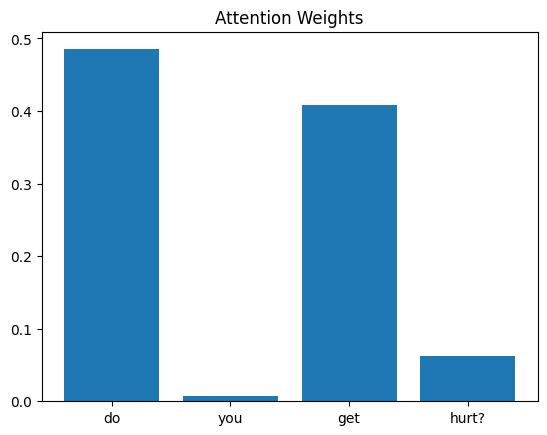

In [15]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Q: How old are you?
   Highest-attention word: 'are' (0.670)
   Predicted answer      : People created me.

Q: Who created you?
   Highest-attention word: 'who' (0.592)
   Predicted answer      : People created me.

Q: Do you have a name?
   Highest-attention word: 'name' (0.920)
   Predicted answer      : I'm better at answering questions.



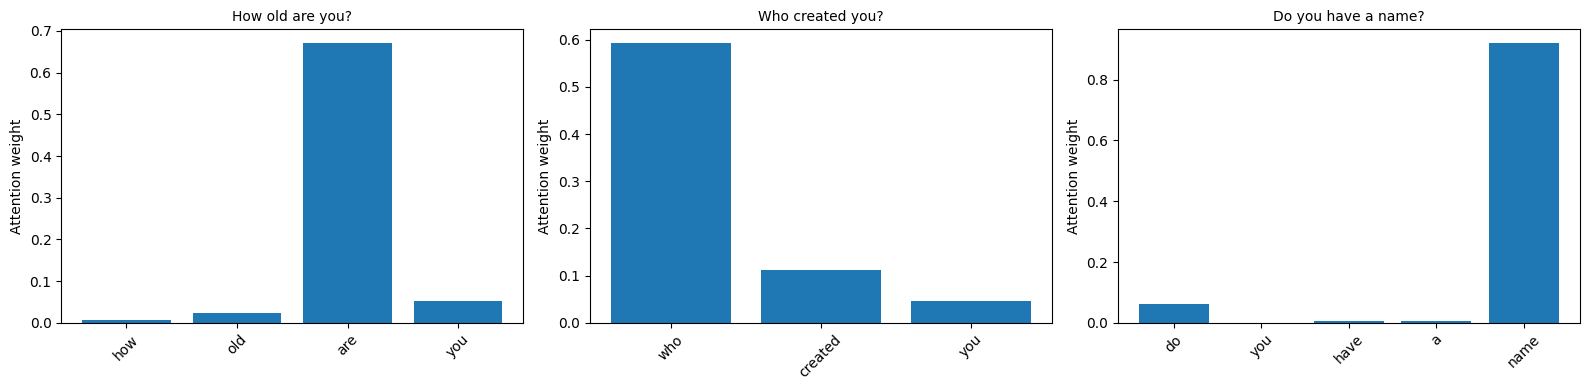

In [16]:
from tensorflow.keras.preprocessing.text import text_to_word_sequence
from tensorflow.keras.preprocessing.sequence import pad_sequences

answers = df.drop_duplicates("answer_id").set_index("answer_id")["answer"].to_dict()

def get_attention(question):
    """Return (words, attention weights for those words, predicted answer id)."""
    q = question.lower()
    words = text_to_word_sequence(q)                       # same cleaning as the Tokenizer
    seq = tokenizer.texts_to_sequences([q])
    x = torch.tensor(pad_sequences(seq, maxlen=X.shape[1], padding="post"), dtype=torch.long)
    model.eval()
    with torch.no_grad():
        logits, w = model(x)
    return words, w[0, :len(words)].tolist(), logits.argmax(1).item()

# Three different questions from the dataset
task1_questions = ["How old are you?", "Who created you?", "Do you have a name?"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, q in zip(axes, task1_questions):
    words, w, pred = get_attention(q)
    ax.bar(words, w)
    ax.set_title(q, fontsize=10)
    ax.set_ylabel("Attention weight")
    ax.tick_params(axis="x", rotation=45)

    top = words[max(range(len(w)), key=lambda i: w[i])]
    print(f"Q: {q}")
    print(f"   Highest-attention word: '{top}' ({max(w):.3f})")
    print(f"   Predicted answer      : {answers[pred]}\n")

plt.tight_layout()
plt.show()

**Answer to Task 1:** Run the cell above and check the printed top words. In general, the model puts most of its weight on the words that separate one answer group from another, such as *old* (age), *created* (creator) and *name* (name), and much less on filler words like *you*, *do*, *have* and *are*, which appear in almost every question and so don't help choose an answer. That is why the highest-weighted word usually looks important for understanding the question. It isn't perfect: the weights come from a tiny RNN trained on ~170 questions, so sometimes a different word, or the last word (the RNN's hidden state there summarises the whole sentence), gets a lot of weight too. Attention shows what the model found useful for its prediction, not a guaranteed human-style notion of importance.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Q: Who built you?
   Weights: who=0.277, built=0.585, you=0.021
   Highest-attention word: 'built'
   Predicted answer      : People created me.

Q: Which company made you?
   Weights: which=0.526, company=0.188, made=0.217, you=0.012
   Highest-attention word: 'which'
   Predicted answer      : People created me.



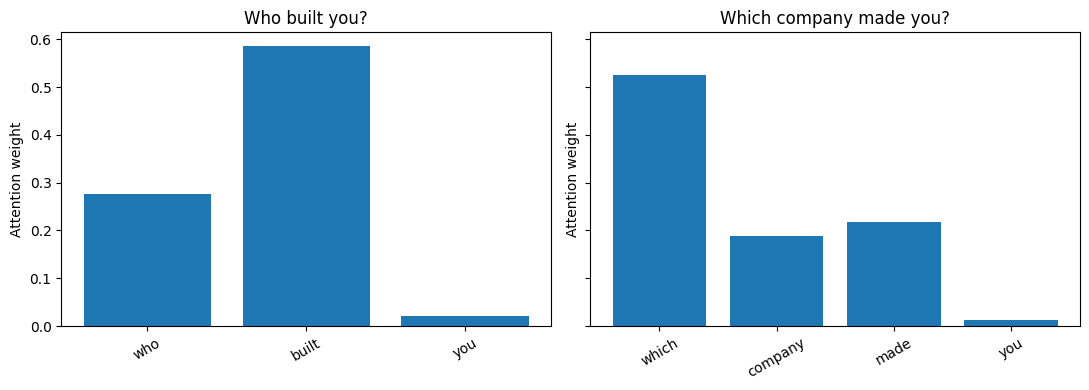

In [17]:
# Two questions with similar meaning but different wording (both ask about the creator)
q_a = "Who built you?"
q_b = "Which company made you?"

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, q in zip(axes, [q_a, q_b]):
    words, w, pred = get_attention(q)
    ax.bar(words, w)
    ax.set_title(q)
    ax.set_ylabel("Attention weight")
    ax.tick_params(axis="x", rotation=30)

    top = words[max(range(len(w)), key=lambda i: w[i])]
    print(f"Q: {q}")
    print(f"   Weights: " + ", ".join(f"{a}={b:.3f}" for a, b in zip(words, w)))
    print(f"   Highest-attention word: '{top}'")
    print(f"   Predicted answer      : {answers[pred]}\n")

plt.tight_layout()
plt.show()

**Answer to Task 2:** Run the cell above and compare the two bar charts. Both questions belong to the same answer group (*"People created me."*), so the model should predict the same answer for both. The words it attends to differ because the sentences use different words (*built* vs *made*, plus *which company*), but in each question the weight tends to fall on the content word that signals "who made you" (*built*, *made*, *company*) rather than on *you* or *who*. This suggests attention doesn't depend on exact words: it learns to focus on whichever tokens carry the meaning relevant to the answer, so different wordings can lead to the same prediction. Limitation: the model can only attend to words it saw in training, and its embeddings are small, so this works best for questions close to the training data.